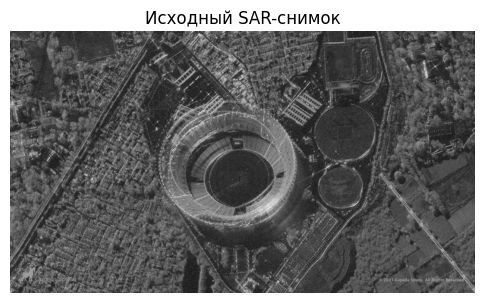

In [2]:
!pip install scikit-image -q
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Загрузка SAR-снимка
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap='gray')
plt.title('Исходный SAR-снимок')
plt.axis('off')
plt.show()

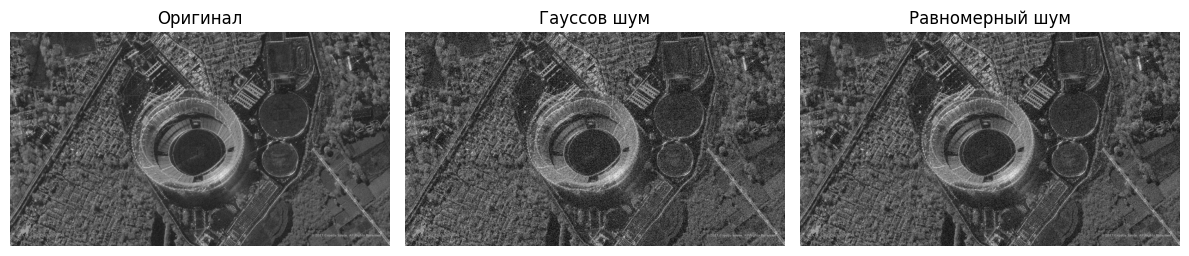

In [3]:
# 1. Гауссов шум
def add_gaussian_noise(img, sigma=30):
    gauss = np.random.normal(0, sigma, img.shape)
    noisy = np.clip(img.astype(np.float32) + gauss, 0, 255)
    return noisy.astype(np.uint8)

# 2. Равномерный шум
def add_uniform_noise(img, a=35):
    uniform = np.random.uniform(-a, a, img.shape)
    noisy = np.clip(img.astype(np.float32) + uniform, 0, 255)
    return noisy.astype(np.uint8)

noisy_gauss = add_gaussian_noise(image_gray, sigma=30)
noisy_uniform = add_uniform_noise(image_gray, a=35)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(image_gray, cmap='gray'); plt.title('Оригинал'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(noisy_gauss, cmap='gray'); plt.title('Гауссов шум'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(noisy_uniform, cmap='gray'); plt.title('Равномерный шум'); plt.axis('off')
plt.tight_layout()
plt.show()

In [4]:
# Фильтрация Гауссова шума
gauss_blur = cv2.GaussianBlur(noisy_gauss, (5, 5), 0)
gauss_bilateral = cv2.bilateralFilter(noisy_gauss, 9, 75, 75)
gauss_nlm = cv2.fastNlMeansDenoising(noisy_gauss, None, h=10, templateWindowSize=7, searchWindowSize=21)

# Фильтрация Равномерного шума
uniform_blur = cv2.blur(noisy_uniform, (5, 5))
uniform_bilateral = cv2.bilateralFilter(noisy_uniform, 9, 75, 75)

# Расчет метрик
def calc_metrics(name, original, processed):
    val_psnr = psnr(original, processed, data_range=255)
    val_ssim = ssim(original, processed, data_range=255)
    print(f"{name:<25} | PSNR: {val_psnr:6.2f} dB | SSIM: {val_ssim:6.4f}")

print("--- Гауссов шум ---")
calc_metrics("Гауссов фильтр", image_gray, gauss_blur)
calc_metrics("Bilateral", image_gray, gauss_bilateral)
calc_metrics("Non-Local Means", image_gray, gauss_nlm)

print("\n--- Равномерный шум ---")
calc_metrics("Box-фильтр (усреднение)", image_gray, uniform_blur)
calc_metrics("Bilateral", image_gray, uniform_bilateral)

--- Гауссов шум ---
Гауссов фильтр            | PSNR:  25.66 dB | SSIM: 0.6778
Bilateral                 | PSNR:  24.88 dB | SSIM: 0.6071
Non-Local Means           | PSNR:  18.77 dB | SSIM: 0.4069

--- Равномерный шум ---
Box-фильтр (усреднение)   | PSNR:  24.76 dB | SSIM: 0.5915
Bilateral                 | PSNR:  25.14 dB | SSIM: 0.6100
